## Part A - Image Representation

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import time

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATASET_DIR = Path("orl_faces")

images = []
labels = []
image_paths = []

for subject_folder in sorted(DATASET_DIR.iterdir()):
    if subject_folder.is_dir() and subject_folder.name.lower().startswith("s"):
        for image_path in sorted(subject_folder.iterdir()):
            if image_path.suffix.lower() in [".pgm", ".png", ".jpg", ".jpeg"]:
                image = Image.open(image_path).convert("L")
                image_array = np.array(image)

                images.append(image_array.flatten())
                labels.append(subject_folder.name)
                image_paths.append(image_path)

X = np.array(images, dtype=np.float64)
y = np.array(labels)

print("Total images:", X.shape[0])
print("Total subjects:", len(np.unique(y)))
print("Image matrix shape:", X.shape)
print("Image dimensions:", images[0].shape)
print("Minimum pixel intensity:", X.min())
print("Maximum pixel intensity:", X.max())

Total images: 400
Total subjects: 40
Image matrix shape: (400, 10304)
Image dimensions: (10304,)
Minimum pixel intensity: 0.0
Maximum pixel intensity: 251.0


Image height and width: (112, 92)
Pixel intensity values:
[[48 49 45 47 49]
 [45 52 39 46 56]
 [45 50 42 51 51]
 [49 46 47 47 50]
 [46 46 47 48 48]]


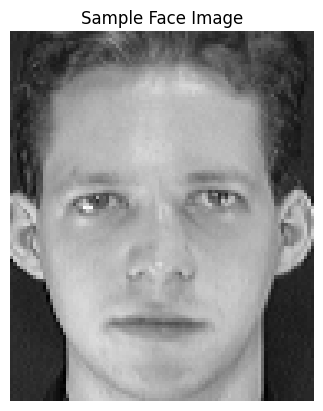

In [8]:
first_image = Image.open(image_paths[0]).convert("L")
first_array = np.array(first_image)

print("Image height and width:", first_array.shape)
print("Pixel intensity values:")
print(first_array[:5, :5])

plt.imshow(first_array, cmap="gray")
plt.title("Sample Face Image")
plt.axis("off")
plt.show()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])
print("Training subjects:", len(np.unique(y_train)))
print("Testing subjects:", len(np.unique(y_test)))

assert set(y_train) == set(y_test)

Training images: 280
Testing images: 120
Training subjects: 40
Testing subjects: 40


## Part B - PCA, Eigenfaces and Compression

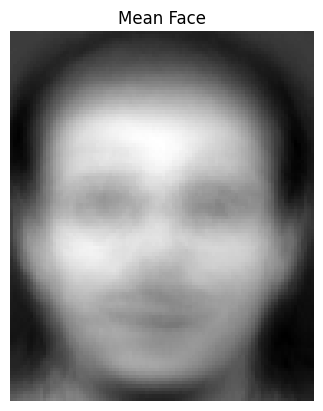

Mean face shape: (10304,)
Centered training matrix: (280, 10304)


In [10]:
mean_face = np.mean(X_train, axis=0)

X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

plt.imshow(mean_face.reshape(first_array.shape), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

print("Mean face shape:", mean_face.shape)
print("Centered training matrix:", X_train_centered.shape)

In [11]:
start = time.time()

covariance_matrix = X_train_centered @ X_train_centered.T

eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

positive = eigenvalues > 1e-10
eigenvalues = eigenvalues[positive]
eigenvectors = eigenvectors[:, positive]

eigenfaces_eig = (
    X_train_centered.T @ eigenvectors
) / np.sqrt(eigenvalues)[None, :]

eigenfaces_eig = eigenfaces_eig.T

eigen_time = time.time() - start

print("Eigenface matrix:", eigenfaces_eig.shape)
print("Eigendecomposition time:", round(eigen_time, 4), "seconds")

Eigenface matrix: (279, 10304)
Eigendecomposition time: 0.3697 seconds


In [12]:
start = time.time()

U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

eigenfaces_svd = Vt

svd_time = time.time() - start

print("SVD eigenface matrix:", eigenfaces_svd.shape)
print("SVD time:", round(svd_time, 4), "seconds")

SVD eigenface matrix: (280, 10304)
SVD time: 3.9527 seconds


In [13]:
variance = singular_values ** 2
explained_variance_ratio = variance / np.sum(variance)

cumulative_variance = np.cumsum(explained_variance_ratio)

n_components_90 = np.searchsorted(
    cumulative_variance, 0.90
) + 1

print("Components needed for 90% variance:", n_components_90)
print("Variance preserved:",
      round(cumulative_variance[n_components_90 - 1] * 100, 2), "%")

n_compare = min(10, len(eigenfaces_eig), len(eigenfaces_svd))

similarities = [
    abs(np.dot(eigenfaces_eig[i], eigenfaces_svd[i]))
    for i in range(n_compare)
]

print("Mean absolute similarity between methods:",
      round(np.mean(similarities), 6))

print("Eigendecomposition time:", round(eigen_time, 4))
print("SVD time:", round(svd_time, 4))

Components needed for 90% variance: 92
Variance preserved: 90.09 %
Mean absolute similarity between methods: 1.0
Eigendecomposition time: 0.3697
SVD time: 3.9527


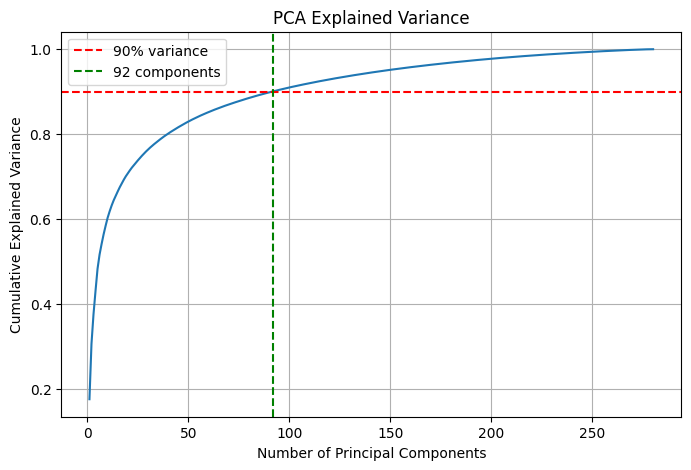

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(0.90, color="red", linestyle="--",
            label="90% variance")
plt.axvline(n_components_90, color="green", linestyle="--",
            label=f"{n_components_90} components")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

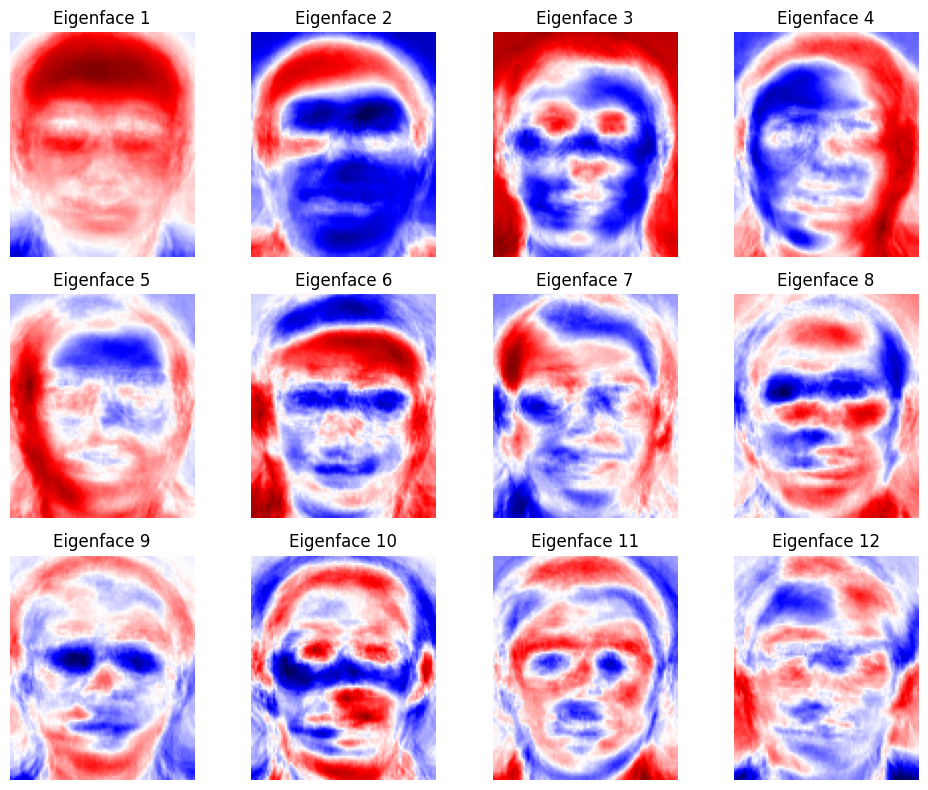

In [15]:
n_show = min(12, len(eigenfaces_svd))

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for i, ax in enumerate(axes.flat):
    if i < n_show:
        eigenface = eigenfaces_svd[i].reshape(first_array.shape)
        limit = np.max(np.abs(eigenface))

        ax.imshow(
            eigenface,
            cmap="seismic",
            vmin=-limit,
            vmax=limit
        )
        ax.set_title(f"Eigenface {i + 1}")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
K = n_components_90

components = eigenfaces_svd[:K]

X_train_pca = X_train_centered @ components.T
X_test_pca = X_test_centered @ components.T

print("Original feature count:", X_train.shape[1])
print("Reduced feature count:", X_train_pca.shape[1])
print("Reduced training matrix:", X_train_pca.shape)
print("Reduced testing matrix:", X_test_pca.shape)

Original feature count: 10304
Reduced feature count: 92
Reduced training matrix: (280, 92)
Reduced testing matrix: (120, 92)


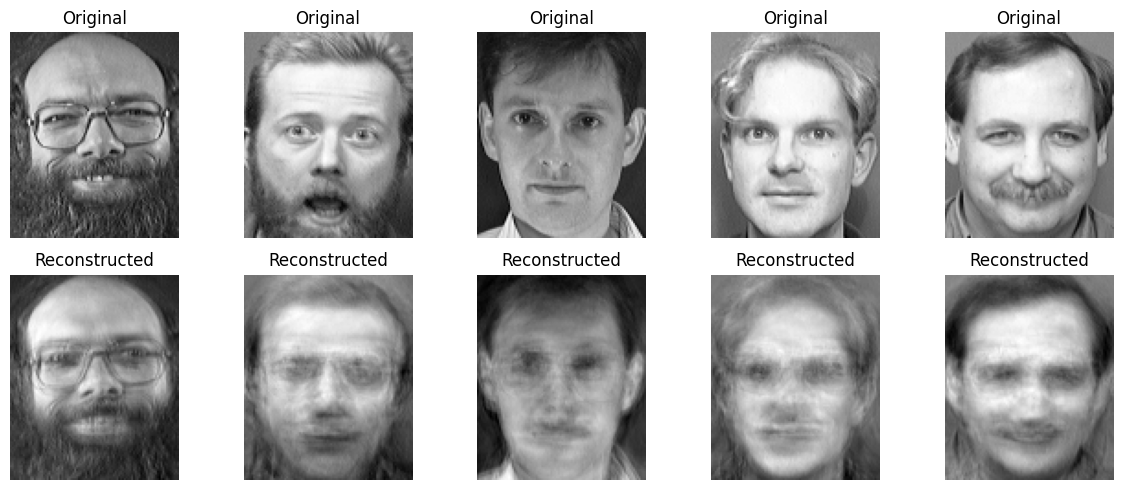

Reconstruction MSE: 317.39
Reconstruction RMSE: 17.82


In [17]:
n_samples = min(5, len(X_test))

reconstructed_faces = (
    X_test_pca[:n_samples] @ components + mean_face
)

fig, axes = plt.subplots(2, n_samples, figsize=(12, 5))

for i in range(n_samples):
    axes[0, i].imshow(
        X_test[i].reshape(first_array.shape),
        cmap="gray"
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        np.clip(
            reconstructed_faces[i], 0, 255
        ).reshape(first_array.shape),
        cmap="gray"
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

mse = np.mean(
    (X_test[:n_samples] - reconstructed_faces) ** 2
)
rmse = np.sqrt(mse)

print("Reconstruction MSE:", round(mse, 2))
print("Reconstruction RMSE:", round(rmse, 2))

In [18]:
original_values = X_train.size
reduced_values = X_train_pca.size

original_storage = original_values * 8
reduced_storage = reduced_values * 8

print("Original pixel values:", original_values)
print("Reduced PCA values:", reduced_values)

print("Original feature storage (MB):",
      round(original_storage / 1e6, 2))

print("Reduced feature storage (MB):",
      round(reduced_storage / 1e6, 2))

print("Feature reduction (%):",
      round((1 - reduced_values / original_values) * 100, 2))

Original pixel values: 2885120
Reduced PCA values: 25760
Original feature storage (MB): 23.08
Reduced feature storage (MB): 0.21
Feature reduction (%): 99.11


## Part C - Recognition in PCA Space

In [19]:
def nearest_neighbor_predict(train_features, train_labels,
                             test_features):

    predictions = []
    nearest_indices = []

    for test_face in test_features:
        distances = np.sqrt(
            np.sum((train_features - test_face) ** 2, axis=1)
        )

        nearest_index = np.argmin(distances)

        predictions.append(train_labels[nearest_index])
        nearest_indices.append(nearest_index)

    return np.array(predictions), np.array(nearest_indices)


pca_predictions, pca_nearest_indices = nearest_neighbor_predict(
    X_train_pca, y_train, X_test_pca
)

pca_accuracy = accuracy_score(y_test, pca_predictions)

print("PCA nearest-neighbor accuracy:",
      round(pca_accuracy * 100, 2), "%")

PCA nearest-neighbor accuracy: 98.33 %


In [20]:
raw_predictions, raw_nearest_indices = nearest_neighbor_predict(
    X_train, y_train, X_test
)

raw_accuracy = accuracy_score(y_test, raw_predictions)

print("Raw-pixel recognition accuracy:",
      round(raw_accuracy * 100, 2), "%")

print("PCA recognition accuracy:",
      round(pca_accuracy * 100, 2), "%")

Raw-pixel recognition accuracy: 98.33 %
PCA recognition accuracy: 98.33 %


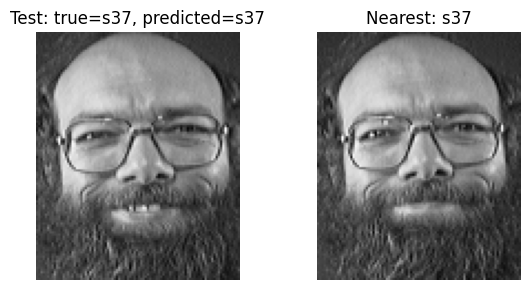

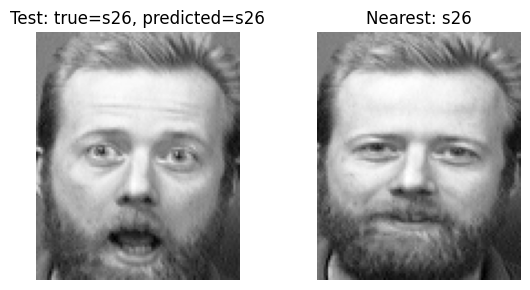

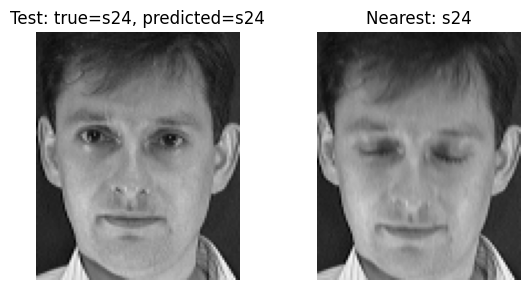

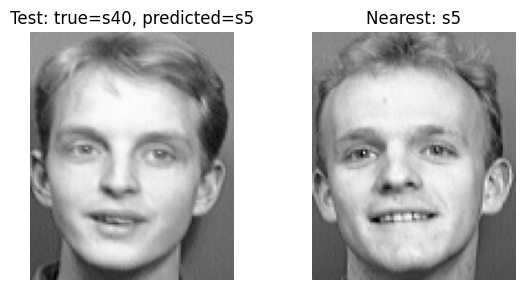

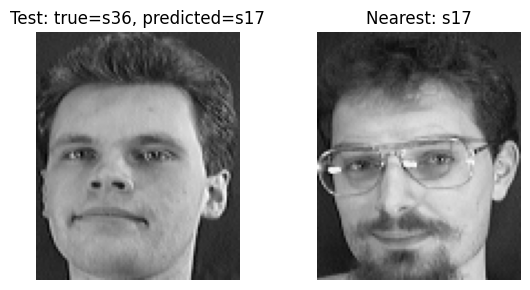

In [21]:
correct = np.where(pca_predictions == y_test)[0]
incorrect = np.where(pca_predictions != y_test)[0]

selected = list(correct[:3]) + list(incorrect[:3])
selected = selected[:6]

for i in selected:
    nearest_index = pca_nearest_indices[i]

    fig, axes = plt.subplots(1, 2, figsize=(6, 3))

    axes[0].imshow(
        X_test[i].reshape(first_array.shape),
        cmap="gray"
    )
    axes[0].set_title(
        f"Test: true={y_test[i]}, predicted={pca_predictions[i]}"
    )
    axes[0].axis("off")

    axes[1].imshow(
        X_train[nearest_index].reshape(first_array.shape),
        cmap="gray"
    )
    axes[1].set_title(f"Nearest: {y_train[nearest_index]}")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

## Part D - Traditional Machine Learning

In [22]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=1),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    "SVM": SVC(kernel="rbf", C=10, gamma="scale")
}

results = [
    {
        "Method": "Raw pixel nearest neighbor",
        "Accuracy": raw_accuracy
    },
    {
        "Method": "PCA nearest neighbor",
        "Accuracy": pca_accuracy
    }
]

trained_models = {}

for name, model in models.items():
    start = time.time()

    model.fit(X_train_pca, y_train)
    predictions = model.predict(X_test_pca)

    elapsed = time.time() - start
    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Method": name,
        "Accuracy": accuracy,
        "Training and prediction time (s)": round(elapsed, 4)
    })

    trained_models[name] = model

comparison_df = pd.DataFrame(results)

display(
    comparison_df.sort_values(
        "Accuracy", ascending=False
    ).reset_index(drop=True)
)

,Method,Accuracy,Training and prediction time (s)
0,SVM,1.000000,0.1248
1,Raw pixel nearest neighbor,0.983333,NaN
2,PCA nearest neighbor,0.983333,NaN
3,KNN,0.983333,12.3131
4,Logistic Regression,0.975000,0.5052


In [1]:
component_counts = sorted(
    set(
        k for k in [10, 20, 30, 40, 60, n_components_90]
        if k <= len(eigenfaces_svd)
    )
)

tuning_results = []

for k in component_counts:
    components_k = eigenfaces_svd[:k]

    train_k = X_train_centered @ components_k.T
    test_k = X_test_centered @ components_k.T

    # Similarity-based baseline
    pred_nn, _ = nearest_neighbor_predict(
        train_k, y_train, test_k
    )

    tuning_results.append({
        "Components": k,
        "Method": "Nearest Neighbor",
        "Accuracy": accuracy_score(y_test, pred_nn)
    })

    # Traditional classifiers
    for name, model in {
        "KNN": KNeighborsClassifier(n_neighbors=1),
        "Logistic Regression": LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ),
        "SVM": SVC(kernel="rbf", C=10, gamma="scale")
    }.items():

        model.fit(train_k, y_train)
        predictions = model.predict(test_k)

        tuning_results.append({
            "Components": k,
            "Method": name,
            "Accuracy": accuracy_score(y_test, predictions)
        })

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.pivot(
        index="Components",
        columns="Method",
        values="Accuracy"
    )
)

for method in tuning_df["Method"].unique():
    subset = tuning_df[tuning_df["Method"] == method]

    plt.plot(
        subset["Components"],
        subset["Accuracy"],
        marker="o",
        label=method
    )

plt.xlabel("Number of PCA Components")
plt.ylabel("Recognition Accuracy")
plt.title("Accuracy vs Number of PCA Components")
plt.legend()
plt.grid(True)
plt.show()

NameError: name 'n_components_90' is not defined